
# 04 · Expression — EMT-transcription-factor readout along the trajectory

Overlay the canonical EMT transcription factors on the trajectory to show which
drivers track the differentiation axis. Under 10x dropout most EMT-TFs are sparsely
detected, so the panel is **detection-gated**: TFs are ranked by detection fraction
and pseudotime gradient, and the informative **early (root-high, declining)** and
**late (terminus-rising)** factors are shown in the house linear layout. For this
LUAD manifold FOXC1 marks the alveolar/AT2-differentiated origin and ZEB1 rises toward
the dedifferentiated terminus. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load signatures manifold and rank EMT-TFs (detection-gated, data-driven)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x); rows.append((g, (x>0).mean(), rho))
df = pd.DataFrame(rows, columns=['TF','detect_frac','rho_t']).sort_values('rho_t')
print(df.round(3).to_string(index=False))
DET = 0.03  # detection floor (10x dropout)
ok = df[df.detect_frac >= DET]
early = ok.iloc[0]['TF']; late = ok.iloc[-1]['TF']
print(f'\ndetection floor {DET}: early(root, declining) = {early} | late(terminus, rising) = {late}')

    TF  detect_frac  rho_t
 FOXC1        0.330 -0.116
 PRRX1        0.055 -0.095
 SNAI1        0.152 -0.083
TWIST2        0.024 -0.057
 FOXC2        0.003  0.040
  ZEB2        0.044  0.061
TWIST1        0.007  0.075
 SNAI2        0.018  0.144
 PRRX2        0.100  0.178
  ZEB1        0.051  0.195

detection floor 0.03: early(root, declining) = FOXC1 | late(terminus, rising) = ZEB1



### EMT-TF expression figure (deliverable)
Two-panel house style (`figsize` per panel 3.5×1.5, pseudotime left→right, `size=30`,
viridis), the derived early/late factors. Titles annotate detection fraction and the
pseudotime Spearman ρ so sparsity is explicit.

saved expression.pdf | shown: ['FOXC1', 'ZEB1']


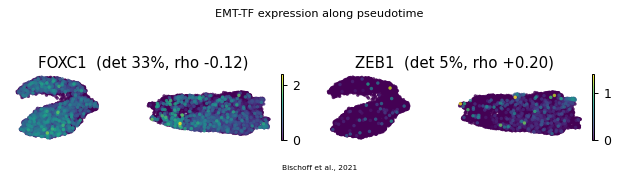

In [4]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
pair = [early, late]
fig, axes = plt.subplots(1, 2, figsize=(7.2,1.6))
for ax,g in zip(axes, pair):
    x = np.asarray(adata[:,g].X.todense()).ravel() if hasattr(adata[:,g].X,'todense') else np.asarray(adata[:,g].X).ravel()
    det = (x>0).mean(); rho,_ = spearmanr(tn, x)
    sc.pl.umap(plot, color=g, cmap='viridis', alpha=.8, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=f'{g}  (det {det:.0%}, rho {rho:+.2f})')
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.suptitle('EMT-TF expression along pseudotime', size=9, y=1.06)
fig.text(.5,-.06,'Bischoff et al., 2021', ha='center', size=6)
fig.tight_layout()
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
print('saved expression.pdf | shown:', pair)